#Aproximação de função utilizando a rede MLP

Realiza a aproximação da onda senoidal utilizando a rede MLP

##Etapa 01
Importar as bibliotecas de aprendizado de máquina e computação científica.

In [1]:
#Bibliotecas de aprendizado de máquina
from tensorflow import keras
from keras.models import Sequential
from keras.layers import Dense

#Bibliotecas de computação científica
import numpy as np
import matplotlib.pyplot as plt

##Etapa 02
Criar a base de dados sintética.

In [2]:
NUM_SAMPLES = 1000

#Conjunto de treinamento
x_train = np.random.uniform(0, 1, NUM_SAMPLES)
x_train = np.sort(x_train, axis=0)
y_train = np.sin(2 * np.pi * x_train)

#Conjunto de validação
x_test = np.random.uniform(0, 1, int(NUM_SAMPLES/3))
x_test = np.sort(x_test, axis=0)
y_test = np.sin(2 * np.pi * x_test)

##Etapa 03
Conhecer a dimensão dos conjuntos de treinamento e validação.

In [3]:
print('x_train', x_train.shape)
print('y_train', y_train.shape)
print('x_test', x_test.shape)
print('y_test', y_test.shape)

x_train (1000,)
y_train (1000,)
x_test (333,)
y_test (333,)


##Etapa 04
Projetando a rede neural MLP utilizando o Keras.

In [4]:
keras.backend.clear_session()
model = Sequential()
model.add(Dense(8, input_dim = 1, activation='relu')), #sigmoid, relu, gelu, elu:  https://keras.io/api/layers/activations
model.add(Dense(1, activation='linear'))

model.summary()

c:\Users\leonardo.flores\Desktop\UFOP\CDD109 - REDES NEURAIS ARTIFICIAIS E DEEP LEARNING\.venv\Lib\site-packages\keras\src\layers\core\dense.py:107: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ dense (Dense)                   │ (None, 8)              │            16 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │             9 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 25 (100.00 B)

 Trainable params: 25 (100.00 B)

 Non-trainable params: 0 (0.00 B)

##Etapa 05
Compilar o modelo.

Optimizer: As opções são encontradas em https://keras.io/api/optimizers/

Loss: As opções são encontradas em https://keras.io/api/losses/

Metrics: As opções são encontradas em https://keras.io/api/metrics/

In [5]:
""" model.compile(optimizer='Adam',
              loss='mse',
              metrics=['mae']) """
otimizador = keras.optimizers.Adam(learning_rate= 0.001)
model.compile(optimizer= otimizador,
              loss='binary_crossentropy',
             metrics=['binary_accuracy'])

##Etapa 06
Treinar o modelo e realizar a validação.

###Critério de parada com controle da função de custo.

Parâmetros:
- monitor: variável monitorada.
- patience: número de épocas aguardadas sem melhoria antes de interromper.
- min_delta=: considera melhoria apenas quando a variável monitorada supera esse valor.
- restore_best_weights=True: recupera os pesos da época com menor erro de validação.

In [6]:
early_stop = keras.callbacks.EarlyStopping(
    monitor='val_loss',
    patience=20,
    min_delta=1e-4,
    restore_best_weights=True
)

In [7]:
history = model.fit(x_train, y_train, epochs=100, batch_size=32, validation_data=(x_test, y_test), callbacks=[early_stop])
plt.plot(history.history['mae'])
plt.plot(history.history['val_mae'])
plt.title('Acurácia do modelo')
plt.ylabel('Erro')
plt.xlabel('Iteração')
plt.legend(['treinamento', 'validação'], loc='upper left')
plt.show()

Epoch 1/100


32/32 ━━━━━━━━━━━━━━━━━━━━ 1s 9ms/step - binary_accuracy: 0.0000e+00 - loss: -0.4192 - val_binary_accuracy: 0.0000e+00 - val_loss: 0.1451
Epoch 2/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 4ms/step - binary_accuracy: 0.0000e+00 - loss: -0.4192 - val_binary_accuracy: 0.0000e+00 - val_loss: 0.1451
Epoch 3/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - binary_accuracy: 0.0000e+00 - loss: -0.4192 - val_binary_accuracy: 0.0000e+00 - val_loss: 0.1451
Epoch 4/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - binary_accuracy: 0.0000e+00 - loss: -0.4192 - val_binary_accuracy: 0.0000e+00 - val_loss: 0.1451
Epoch 5/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 6ms/step - binary_accuracy: 0.0000e+00 - loss: -0.4192 - val_binary_accuracy: 0.0000e+00 - val_loss: 0.1451
Epoch 6/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 7ms/step - binary_accuracy: 0.0000e+00 - loss: -0.4192 - val_binary_accuracy: 0.0000e+00 - val_loss: 0.1451
Epoch 7/100
32/32 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step - binary_accuracy: 0.0000e+00 - loss: -0.4192 - val_binary_ac

KeyError: 'mae'

##Etapa 07
Realizar algumas predições.

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 5ms/step 


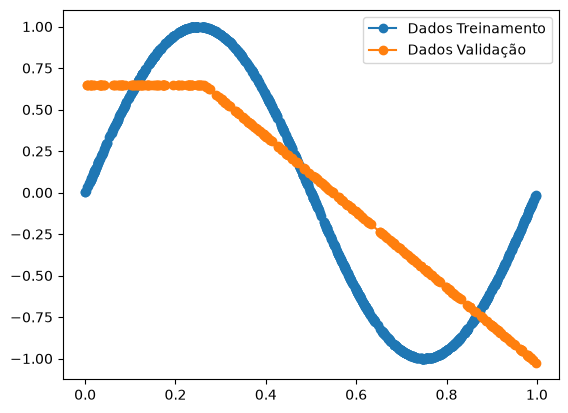

In [ ]:
y_pred = model.predict(x_test)

plt.plot(x_train, y_train, '-o', label='Dados Treinamento')
plt.plot(x_test, y_pred, '-o', label='Dados Validação')
plt.legend()

In [ ]:
loss, metrica= model.evaluate(x_test, y_test)
print('Loss', loss)
print('Metrica', metrica)

11/11 ━━━━━━━━━━━━━━━━━━━━ 0s 3ms/step - loss: 0.1670 - mae: 0.3551 
Loss 0.16696111857891083
Metrica 0.35513821244239807
